In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

We initialize the path to get the raw data and begin the EDA preprocessing.

In [2]:
raw_path = Path("../data/raw")

Here we put our SP500 and VIX into DataFrame to begin the analysis of our raw data.

In [3]:
sp = pd.read_csv(raw_path / "SP500.csv", sep = ";", skiprows=[1,2], index_col=0, parse_dates=True) #we skip line 2 and 3 because its header informations
vix = pd.read_csv(raw_path / "VIX.csv", sep = ";", skiprows=[1,2], index_col=0, parse_dates=True)

sp.index.name = "Date"
vix.index.name = "Date"

print(sp.head())
print(vix.head())


                  Close         High          Low         Open      Volume
Date                                                                      
2000-01-03  1455.219971  1478.000000  1438.359985  1469.250000   931800000
2000-01-04  1399.420044  1455.219971  1397.430054  1455.219971  1009000000
2000-01-05  1402.109985  1413.270020  1377.680054  1399.420044  1085500000
2000-01-06  1403.449951  1411.900024  1392.099976  1402.109985  1092300000
2000-01-07  1441.469971  1441.469971  1400.729980  1403.449951  1225200000
                Close       High        Low       Open  Volume
Date                                                          
2000-01-03  24.209999  26.150000  23.980000  24.360001       0
2000-01-04  27.010000  27.180000  24.799999  24.940001       0
2000-01-05  26.410000  29.000000  25.850000  27.980000       0
2000-01-06  25.730000  26.709999  24.700001  26.680000       0
2000-01-07  21.719999  25.170000  21.719999  25.139999       0


Lets get some informations and descriptions from our raw data. 

In [4]:
sp.info()
vix.info()
print(sp.describe())
vix.describe()

<class 'pandas.DataFrame'>
DatetimeIndex: 6763 entries, 2000-01-03 to 2026-11-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   6763 non-null   float64
 1   High    6763 non-null   float64
 2   Low     6763 non-null   float64
 3   Open    6763 non-null   float64
 4   Volume  6763 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 317.0 KB
<class 'pandas.DataFrame'>
DatetimeIndex: 6765 entries, 2000-01-03 to 2026-11-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   6765 non-null   float64
 1   High    6765 non-null   float64
 2   Low     6765 non-null   float64
 3   Open    6765 non-null   float64
 4   Volume  6765 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 317.1 KB
             Close         High          Low         Open        Volume
count  6763.000000  6763.000000  6763.000000  6763.000000  6.763000e+03
mean   2

,Close,High,Low,Open,Volume
count,6765.000000,6765.000000,6765.000000,6765.000000,6765.0
mean,19.790912,20.849935,19.023038,19.937163,0.0
std,8.257159,8.899221,7.712897,8.317389,0.0
min,9.140000,9.310000,8.560000,9.010000,0.0
25%,14.090000,14.760000,13.660000,14.180000,0.0
50%,17.750000,18.690001,17.070000,17.860001,0.0
75%,23.110001,24.299999,22.240000,23.240000,0.0
max,82.690002,89.529999,72.760002,82.690002,0.0


We can see that the VIX have a volume of 0, which is normal because the VIX is not a tradeable asset, it represents the implied volatility.
And for the S&P500, globally there is not something strange, but the min volume is equal to 0, maybe there is something wrong with it. Maybe its a mistake from Yahoo Finance, because the 0 is not a NaN, it's not detect by pandas, so lets transform the 0 into the previous value from the volume measure of the S&P500. And since the volume of the VIX is equal to zero everytime, lets get rid of it. 


S&P 500 cleaning 

In [5]:
sp["Volume"] = sp["Volume"].replace(0, np.nan).ffill()

Lets check again if the 0 value dissapear. 

In [6]:
sp.describe()

,Close,High,Low,Open,Volume
count,6763.000000,6763.000000,6763.000000,6763.000000,6.763000e+03
mean,2435.686460,2449.081314,2420.684591,2435.436969,3.485943e+09
std,1691.434959,1699.034071,1683.139320,1691.459636,1.538509e+09
min,676.530029,695.270020,666.789978,679.280029,3.560700e+08
25%,1218.799988,1225.604980,1211.375000,1219.070007,2.395525e+09
50%,1634.959961,1644.680054,1628.050049,1634.199951,3.570760e+09
75%,3093.619995,3110.810059,3075.940063,3090.015015,4.361130e+09
max,7818.930176,7844.520020,7805.959961,7813.040039,1.145623e+10


No problem from the S&P500 now.

VIX cleaning 

In [7]:
# check redundancy between columns before dropping them
print(vix[["Open", "High", "Low", "Close"]].corr()) 

           Open      High       Low     Close
Open   1.000000  0.986339  0.991723  0.981753
High   0.986339  1.000000  0.982602  0.990987
Low    0.991723  0.982602  1.000000  0.988880
Close  0.981753  0.990987  0.988880  1.000000


We can see that the column are very correlated, so we can get rid of them.

In [8]:
# intraday range of the VIX ("volatility of volatility"), computed before dropping High/Low
vix["VIX_range"] = (vix["High"] - vix["Low"]) / vix["Close"]

In [9]:
# Keep only the close (latest information at forecast time) and the range
vix = vix[["Close", "VIX_range"]].rename(columns={"Close": "VIX"})

In [10]:
vix.describe()

,VIX,VIX_range
count,6765.000000,6765.000000
mean,19.790912,0.087330
std,8.257159,0.057987
min,9.140000,0.011401
25%,14.090000,0.051077
50%,17.750000,0.073605
75%,23.110001,0.105381
max,82.690002,1.097744


To sum up, we have now basically clean our two raw csv from the thing that we don't going to use for our analysis. 

To continue our EDA, we are going to fusion the two raw data into one csv, to work with it from now to the end of our project. 

In [11]:
df = sp.join(vix, how="inner")

In [12]:
print(vix.index.difference(sp.index))   # dates in VIX but not in S&P 500
print(len(sp), len(vix), len(df))

DatetimeIndex(['2026-05-25', '2026-09-07'], dtype='datetime64[us]', name='Date', freq=None)
6763 6765 6763


Why there is different lenght, its because the VIX have two more date : Memorial Day and Labor Day. This are federal holiday and the S&P500 are not priced. 

Lets check info and description of our clean new csv.

In [13]:
df.describe()

,Close,High,Low,Open,Volume,VIX,VIX_range
count,6763.000000,6763.000000,6763.000000,6763.000000,6.763000e+03,6763.000000,6763.000000
mean,2435.686460,2449.081314,2420.684591,2435.436969,3.485943e+09,19.792049,0.087350
std,1691.434959,1699.034071,1683.139320,1691.459636,1.538509e+09,8.258108,0.057985
min,676.530029,695.270020,666.789978,679.280029,3.560700e+08,9.140000,0.011401
25%,1218.799988,1225.604980,1211.375000,1219.070007,2.395525e+09,14.090000,0.051095
50%,1634.959961,1644.680054,1628.050049,1634.199951,3.570760e+09,17.750000,0.073625
75%,3093.619995,3110.810059,3075.940063,3090.015015,4.361130e+09,23.110001,0.105389
max,7818.930176,7844.520020,7805.959961,7813.040039,1.145623e+10,82.690002,1.097744


Everything seems correct.

We now are going to compute the features that we need for now to create the dataset that we will use to begin the machine learning stuff. 

In [14]:
# daily log-return (percentage change in the value of an asset over time)
df["r"] = np.log(df["Close"] / df["Close"].shift(1))

# features 
df["r_lag1"] = df["r"].shift(1) # yesterday's return
df["abs_r"] = df["r"].abs() # size of today's move
for w in [5, 20, 60]:
    df[f"vol_{w}"] = df["r"].rolling(w).std() # rolling volatility (5, 20, 60 days)
df["range"] = (df["High"] - df["Low"]) / df["Close"] # intraday range of the S&P 500

df["target"] = df["r"].shift(-1) # target: tomorrow's return

df = df.dropna() # we write this line to keep the data clean at the end

# we save only the useful columns
cols = ["r", "r_lag1", "abs_r", "vol_5", "vol_20", "vol_60", "range", "VIX", "VIX_range", "target"]
df[cols].to_csv("../data/processed/dataset.csv", sep=";")

In [ ]:
print("Mean :", df["r"].mean())
print("Std :", df["r"].std())
print("Skewness :", stats.skew(df["r"]))
print("Kurtosis :", stats.kurtosis(df["r"]))

Mean : 0.00023278323631404258
Std : 0.01208539046864523
Skewness : -0.35856356215962787
Kurtosis : 10.839471415736506


Skewness < 0: large losses are more frequent than large gains. Kurtosis ≈ 11 ≫ 0 (normal distribution): fat tails, extreme losses are much more frequent than a Gaussian model predicts → a Gaussian VaR would underestimate risk.

Now some graphs to explicite our data : 

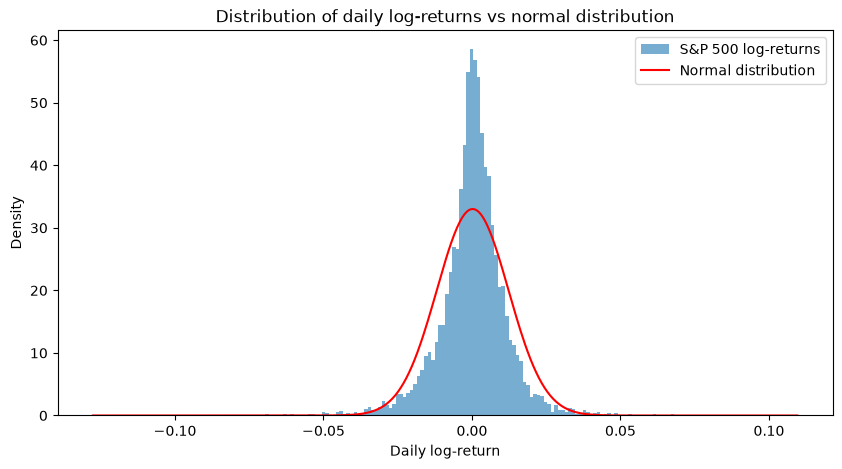

Empirical 1 % quantile : -0.03455173067811596
Normal 1 % quantile    : -0.02788203918737223


In [16]:
# histogram of returns vs normal distribution
r = df["r"]
x = np.linspace(r.min(), r.max(), 500)

plt.figure(figsize=(10, 5))
plt.hist(r, bins=200, density=True, alpha=0.6, label="S&P 500 log-returns")
plt.plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r", label="Normal distribution")
plt.xlabel("Daily log-return")
plt.ylabel("Density")
plt.title("Distribution of daily log-returns vs normal distribution")
plt.legend()
plt.show()

# 1 % quantile: empirical vs normal
print("Empirical 1 % quantile :", r.quantile(0.01))
print("Normal 1 % quantile    :", stats.norm.ppf(0.01, r.mean(), r.std()))

The returns are not normal : the peak is higher and there is more values in the tails. The 1 % empirical quantile is -3.46 % vs -2.79 % for the normal one, so a gaussian VaR would underestimate the risk.

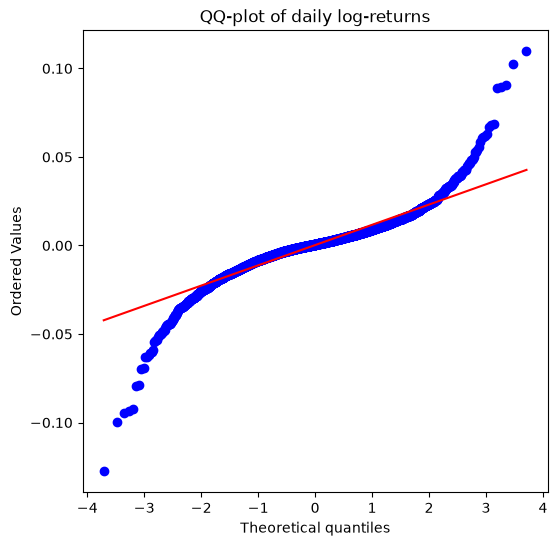

In [17]:
# QQ-plot against the normal distribution
plt.figure(figsize=(6, 6))
stats.probplot(df["r"], dist="norm", plot=plt)
plt.title("QQ-plot of daily log-returns")
plt.show()

At the extremities, the points go away from the red line : the extreme returns are bigger than what the normal distribution predicts.

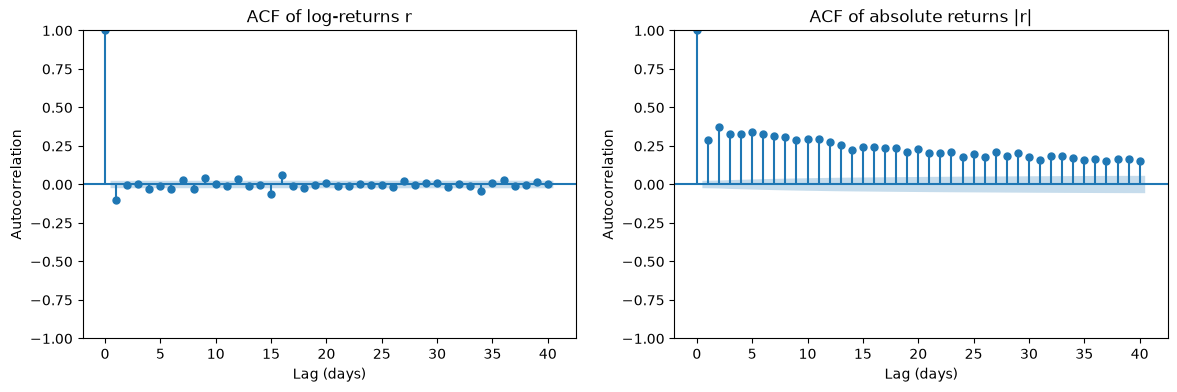

In [ ]:
# autocorrelation of returns and absolute returns
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df["r"], lags=40, ax=ax[0], title="ACF of log-returns r")
plot_acf(df["abs_r"], lags=40, ax=ax[1], title="ACF of absolute returns |r|")
for a in ax:
    a.set_xlabel("Lag (days)")
    a.set_ylabel("Autocorrelation")
plt.show()

r has almost no autocorrelation, so we can't predict the direction of the market. But |r| is autocorrelated (around 0.3, even after 40 days) : big moves follow big moves (volatility clustering). That's why our volatility features are useful for the VaR.

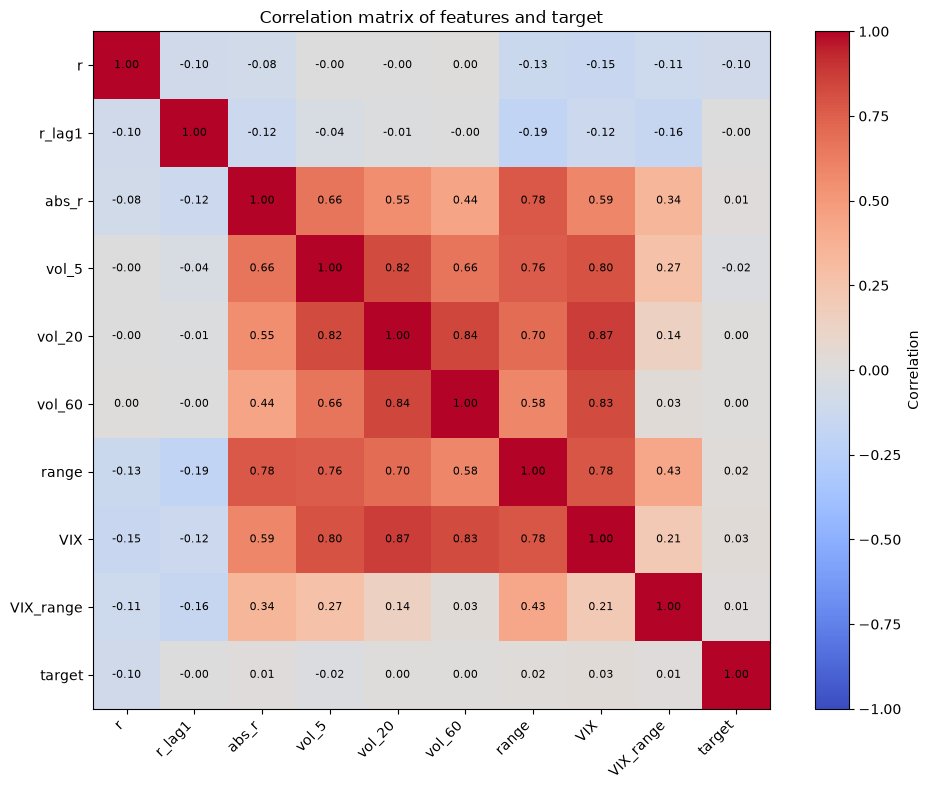

In [19]:
# correlation between features and target
cols = ["r", "r_lag1", "abs_r", "vol_5", "vol_20", "vol_60", "range", "VIX", "VIX_range", "target"]
corr = df[cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation matrix of features and target")
plt.tight_layout()
plt.show()

The volatility features (vol_5, vol_20, vol_60, range, VIX) are very correlated between them (up to 0.87), so there is redundancy. The correlations with the target are close to 0, but it's normal : we predict the 1 % quantile, not the mean.